In [1]:
# Встановлення залежностей (розкоментуйте за необхідності)
# !pip install torch mlflow ray[tune] scikit-learn pandas numpy matplotlib seaborn

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from copy import deepcopy
import os, tempfile

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset

import mlflow
import mlflow.pytorch

import ray
from ray import tune
from ray.tune.schedulers import ASHAScheduler

np.random.seed(42)
torch.manual_seed(42)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f'PyTorch  : {torch.__version__}')
print(f'MLflow   : {mlflow.__version__}')
print(f'Ray      : {ray.__version__}')
print(f'Device   : {DEVICE}')

2026-05-10 23:27:23,608	INFO util.py:154 -- Outdated packages:
  ipywidgets==7.8.1 found, needs ipywidgets>=8
Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
2026-05-10 23:27:23,730	INFO util.py:154 -- Outdated packages:
  ipywidgets==7.8.1 found, needs ipywidgets>=8
Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


PyTorch  : 2.7.1
MLflow   : 3.12.0
Ray      : 2.55.1
Device   : cpu


In [3]:
housing = fetch_california_housing()
X = pd.DataFrame(housing.data, columns=housing.feature_names)
y = pd.Series(housing.target, name='MedHouseVal')

print(f'Форма X: {X.shape}  |  Форма y: {y.shape}')
display(X.describe().round(3))

Форма X: (20640, 8)  |  Форма y: (20640,)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.000,20640.000,20640.000,20640.000,20640.000,20640.000,20640.000,20640.000
mean,3.871,28.639,5.429,1.097,1425.477,3.071,35.632,-119.570
std,1.900,12.586,2.474,0.474,1132.462,10.386,2.136,2.004
min,0.500,1.000,0.846,0.333,3.000,0.692,32.540,-124.350
25%,2.563,18.000,4.441,1.006,787.000,2.430,33.930,-121.800
50%,3.535,29.000,5.229,1.049,1166.000,2.818,34.260,-118.490
75%,4.743,37.000,6.052,1.100,1725.000,3.282,37.710,-118.010
max,15.000,52.000,141.909,34.067,35682.000,1243.333,41.950,-114.310


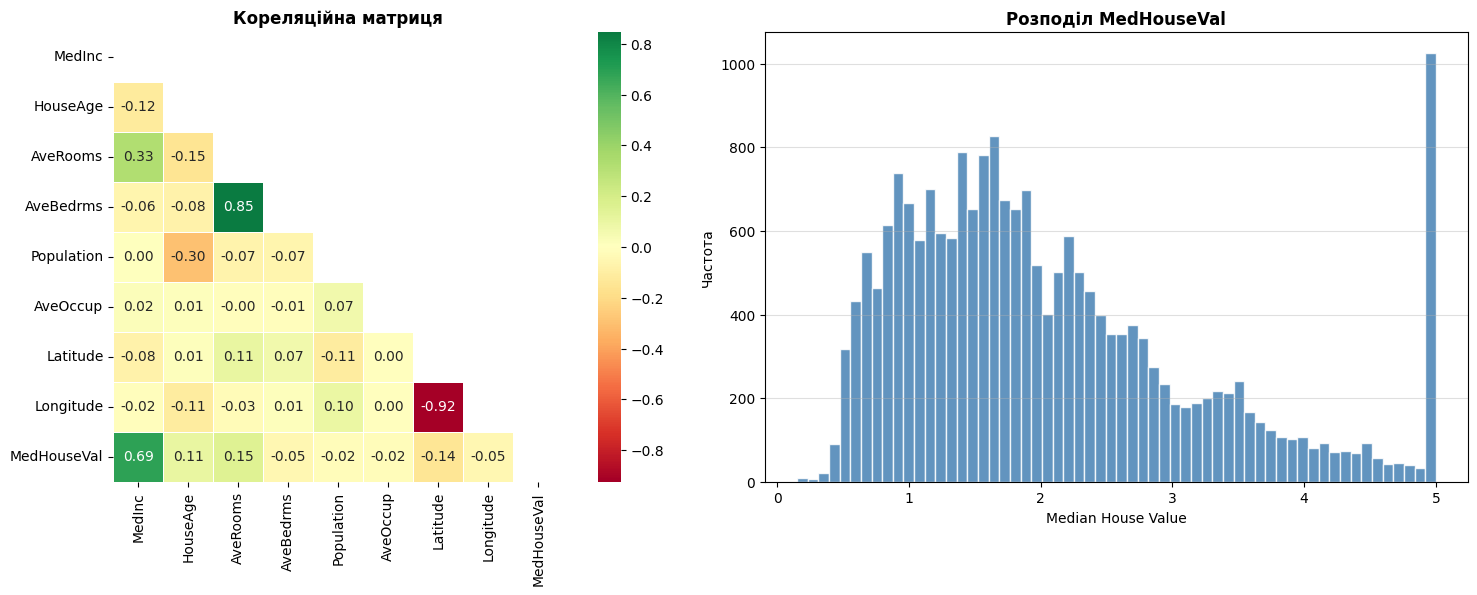

Кореляції з MedHouseVal:
MedHouseVal    1.000000
MedInc         0.688075
AveRooms       0.151948
HouseAge       0.105623
AveOccup      -0.023737
Population    -0.024650
Longitude     -0.045967
AveBedrms     -0.046701
Latitude      -0.144160


In [4]:
# Кореляційна матриця
df_full = pd.concat([X, y], axis=1)
corr = df_full.corr()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Heatmap
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)),
            annot=True, fmt='.2f', cmap='RdYlGn', center=0,
            ax=axes[0], linewidths=0.5, square=True)
axes[0].set_title('Кореляційна матриця', fontweight='bold')

# Розподіл цільової змінної
axes[1].hist(y, bins=60, color='steelblue', edgecolor='white', alpha=0.85)
axes[1].set_title('Розподіл MedHouseVal', fontweight='bold')
axes[1].set_xlabel('Median House Value')
axes[1].set_ylabel('Частота')
axes[1].grid(axis='y', alpha=0.4)

plt.tight_layout()
plt.savefig('lab2_eda.png', dpi=120, bbox_inches='tight')
plt.show()

print('Кореляції з MedHouseVal:')
print(corr['MedHouseVal'].sort_values(ascending=False).to_string())

In [5]:
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_arr = X.values.astype(np.float32)
y_arr = y.values.astype(np.float32).reshape(-1, 1)

X_temp, X_test_raw, y_temp, y_test_raw = train_test_split(
    X_arr, y_arr, test_size=0.15, random_state=42)
X_train_raw, X_val_raw, y_train_raw, y_val_raw = train_test_split(
    X_temp, y_temp, test_size=0.1765, random_state=42)

X_train = scaler_X.fit_transform(X_train_raw).astype(np.float32)
X_val   = scaler_X.transform(X_val_raw).astype(np.float32)
X_test  = scaler_X.transform(X_test_raw).astype(np.float32)

y_train = scaler_y.fit_transform(y_train_raw).astype(np.float32).flatten()
y_val   = scaler_y.transform(y_val_raw).astype(np.float32).flatten()
y_test  = scaler_y.transform(y_test_raw).astype(np.float32).flatten()

print(f'Train : {X_train.shape[0]:>6}  Val : {X_val.shape[0]:>5}  Test : {X_test.shape[0]:>5}')
print(f'Input dim : {X_train.shape[1]}')

Train :  14447  Val :  3097  Test :  3096
Input dim : 8


In [6]:
def make_loaders(X_tr, y_tr, X_v, y_v, batch_size=256):
    tr_ds = TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(y_tr))
    v_ds  = TensorDataset(torch.from_numpy(X_v),  torch.from_numpy(y_v))
    tr_ld = DataLoader(tr_ds, batch_size=batch_size, shuffle=True,  drop_last=False)
    v_ld  = DataLoader(v_ds,  batch_size=batch_size, shuffle=False, drop_last=False)
    return tr_ld, v_ld

# Тестовий тензор
X_test_t = torch.from_numpy(X_test)
y_test_t = torch.from_numpy(y_test)

print('DataLoader готовий.')
print(f'Приклад batch shape: {next(iter(make_loaders(X_train,y_train,X_val,y_val)[0]))[0].shape}')

DataLoader готовий.
Приклад batch shape: torch.Size([256, 8])


In [7]:
def get_activation(name):
    """Повертає модуль активації за рядком."""
    if name == 'relu':
        return nn.ReLU()
    elif name == 'leaky_relu':
        return nn.LeakyReLU(negative_slope=0.2)
    elif name == 'gelu':
        return nn.GELU()
    raise ValueError(f'Unknown activation: {name}')


class BasicNet(nn.Module):
    """Базова FF мережа: 2 приховані шари."""
    def __init__(self, input_dim=8, activation='relu'):
        super().__init__()
        act = get_activation(activation)
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            deepcopy(act),
            nn.Linear(128, 64),
            deepcopy(act),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)


class AdvancedNet(nn.Module):
    """Розширена мережа: Dropout + BatchNorm + weight_decay (L2)."""
    def __init__(self, input_dim=8, activation='relu', dropout=0.3):
        super().__init__()
        act = get_activation(activation)
        self.net = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            deepcopy(act),
            nn.Dropout(dropout),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            deepcopy(act),
            nn.Dropout(dropout),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            deepcopy(act),
            nn.Dropout(dropout / 2),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)


# Перевірка
m = BasicNet(8, 'relu')
dummy = torch.randn(4, 8)
out = m(dummy)
print(f'BasicNet output shape : {out.shape}')

m2 = AdvancedNet(8, 'gelu')
out2 = m2(dummy)
print(f'AdvancedNet output shape : {out2.shape}')

total_params = sum(p.numel() for p in m.parameters())
total_params2 = sum(p.numel() for p in m2.parameters())
print(f'BasicNet   params : {total_params:,}')
print(f'AdvancedNet params: {total_params2:,}')

BasicNet output shape : torch.Size([4])
AdvancedNet output shape : torch.Size([4])
BasicNet   params : 9,473
AdvancedNet params: 44,417


In [8]:
EPOCHS = 15
INPUT_DIM = X_train.shape[1]
results_pt = {}   # зберігатимемо метрики

def train_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, count = 0.0, 0
    for Xb, yb in loader:
        Xb, yb = Xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        pred = model(Xb)
        loss = criterion(pred, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(yb)
        count += len(yb)
    return total_loss / count


def eval_epoch(model, loader, criterion):
    model.eval()
    total_loss, count = 0.0, 0
    with torch.no_grad():
        for Xb, yb in loader:
            Xb, yb = Xb.to(DEVICE), yb.to(DEVICE)
            pred = model(Xb)
            loss = criterion(pred, yb)
            total_loss += loss.item() * len(yb)
            count += len(yb)
    return total_loss / count


def predict_inverse(model, X_tensor):
    model.eval()
    with torch.no_grad():
        preds_scaled = model(X_tensor.to(DEVICE)).cpu().numpy()
    return scaler_y.inverse_transform(preds_scaled.reshape(-1, 1)).flatten()


def compute_metrics(model, X_tensor, y_scaled):
    y_pred = predict_inverse(model, X_tensor)
    y_true = scaler_y.inverse_transform(y_scaled.reshape(-1, 1)).flatten()
    mse  = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae  = mean_absolute_error(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)
    acc_10 = float(np.mean(np.abs((y_true - y_pred) / np.where(y_true == 0, 1e-8, y_true)) <= 0.1) * 100)
    return {'mse': mse, 'rmse': rmse, 'mae': mae, 'r2': r2, 'acc_10': acc_10}


def _mlflow_save_model(model, artifact_path='model'):
    """Зберігає state_dict моделі як MLflow артефакт (без mlflow.pytorch.log_model)."""
    import tempfile, os as _os
    with tempfile.TemporaryDirectory() as tmpdir:
        mpath = _os.path.join(tmpdir, 'model.pth')
        torch.save(model.state_dict(), mpath)
        mlflow.log_artifact(mpath, artifact_path=artifact_path)


def full_train(model_class, model_kwargs, name, arch_type, activation, lr,
               batch_size=256, weight_decay=0.0):
    """Повне навчання з MLflow."""
    model = model_class(**model_kwargs).to(DEVICE)
    train_loader, val_loader = make_loaders(X_train, y_train, X_val, y_val, batch_size)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=3)

    history = {'train_loss': [], 'val_loss': []}
    best_val, best_state, patience_cnt = float('inf'), None, 0

    with mlflow.start_run(run_name=name):
        mlflow.log_param('architecture', arch_type)
        mlflow.log_param('activation', activation)
        mlflow.log_param('learning_rate', lr)
        mlflow.log_param('epochs', EPOCHS)
        mlflow.log_param('batch_size', batch_size)
        mlflow.log_param('weight_decay', weight_decay)
        mlflow.log_param('optimizer', 'Adam')

        for epoch in range(1, EPOCHS + 1):
            tr_loss = train_epoch(model, train_loader, criterion, optimizer)
            vl_loss = eval_epoch(model, val_loader, criterion)
            scheduler.step(vl_loss)
            history['train_loss'].append(tr_loss)
            history['val_loss'].append(vl_loss)
            mlflow.log_metric('train_loss', tr_loss, step=epoch)
            mlflow.log_metric('val_loss',   vl_loss, step=epoch)
            if vl_loss < best_val:
                best_val = vl_loss
                best_state = deepcopy(model.state_dict())
                patience_cnt = 0
            else:
                patience_cnt += 1
            if patience_cnt >= 5:
                print(f'  Early stop at epoch {epoch}')
                break

        model.load_state_dict(best_state)
        met = compute_metrics(model, X_test_t, y_test)
        for k, v in met.items():
            mlflow.log_metric(f'test_{k}', v)
        _mlflow_save_model(model, artifact_path='model')

    print(f'[{name:45s}] RMSE={met["rmse"]:.4f}  MAE={met["mae"]:.4f}  R²={met["r2"]:.4f}  Accuracy@10%={met["acc_10"]:.2f}%')
    return history, met, model

In [9]:
mlflow.set_tracking_uri('./mlruns_lab2')
mlflow.set_experiment('California_Housing_PyTorch')

print('MLflow tracking URI :', mlflow.get_tracking_uri())
print('Experiment          : California_Housing_PyTorch')

MLflow tracking URI : ./mlruns_lab2
Experiment          : California_Housing_PyTorch


In [10]:
print('=' * 75)
print('БАЗОВІ МОДЕЛІ — PyTorch')
print('=' * 75)

histories_basic_pt = {}

for act in ['relu', 'leaky_relu', 'gelu']:
    hist, met, _ = full_train(
        BasicNet,
        {'input_dim': INPUT_DIM, 'activation': act},
        name=f'basic_{act}',
        arch_type='basic',
        activation=act,
        lr=0.001
    )
    histories_basic_pt[act] = hist
    results_pt[f'basic_{act}'] = met

БАЗОВІ МОДЕЛІ — PyTorch
[basic_relu                                   ] RMSE=0.5698  MAE=0.3999  R²=0.7523  Accuracy@10%=32.14%
[basic_leaky_relu                             ] RMSE=0.5978  MAE=0.4208  R²=0.7273  Accuracy@10%=31.04%
[basic_gelu                                   ] RMSE=0.5862  MAE=0.4183  R²=0.7378  Accuracy@10%=31.20%


In [11]:
print('=' * 75)
print('РОЗШИРЕНІ МОДЕЛІ — PyTorch')
print('=' * 75)

histories_adv_pt = {}

for act in ['relu', 'gelu']:
    hist, met, _ = full_train(
        AdvancedNet,
        {'input_dim': INPUT_DIM, 'activation': act, 'dropout': 0.3},
        name=f'advanced_{act}',
        arch_type='advanced',
        activation=act,
        lr=0.001,
        weight_decay=1e-4
    )
    histories_adv_pt[act] = hist
    results_pt[f'advanced_{act}'] = met

РОЗШИРЕНІ МОДЕЛІ — PyTorch
[advanced_relu                                ] RMSE=0.5871  MAE=0.4045  R²=0.7370  Accuracy@10%=32.11%
  Early stop at epoch 10
[advanced_gelu                                ] RMSE=0.6167  MAE=0.4307  R²=0.7098  Accuracy@10%=29.97%


In [12]:
# Ініціалізація Ray (якщо ще не запущено)
if not ray.is_initialized():
    ray.init(ignore_reinit_error=True, num_cpus=2, log_to_driver=False)
    print('Ray initialized.')

# Передаємо дані через tune.with_parameters (уникаємо великих об'єктів у config)
X_train_ref = ray.put(X_train)
y_train_ref = ray.put(y_train)
X_val_ref   = ray.put(X_val)
y_val_ref   = ray.put(y_val)

2026-05-10 23:27:35,759	INFO worker.py:2012 -- Started a local Ray instance.


Ray initialized.


In [13]:
def raytune_trainable(config):
    """Trainable-функція для Ray Tune."""
    import torch, torch.nn as nn, torch.optim as optim
    from torch.utils.data import TensorDataset, DataLoader
    import numpy as np, ray

    X_tr = ray.get(config['X_train_ref'])
    y_tr = ray.get(config['y_train_ref'])
    X_v  = ray.get(config['X_val_ref'])
    y_v  = ray.get(config['y_val_ref'])

    act_name = config['activation']
    dropout  = config['dropout']

    def get_act(name):
        if name == 'relu':      return nn.ReLU()
        if name == 'leaky_relu': return nn.LeakyReLU(0.2)
        return nn.GELU()

    act = get_act(act_name)
    from copy import deepcopy

    model = nn.Sequential(
        nn.Linear(8, config['hidden1']),
        nn.BatchNorm1d(config['hidden1']),
        deepcopy(act), nn.Dropout(dropout),
        nn.Linear(config['hidden1'], config['hidden2']),
        nn.BatchNorm1d(config['hidden2']),
        deepcopy(act), nn.Dropout(dropout / 2),
        nn.Linear(config['hidden2'], config['hidden3']),
        deepcopy(act),
        nn.Linear(config['hidden3'], 1)
    )

    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=config['lr'],
                            weight_decay=config['weight_decay'])

    tr_ds = TensorDataset(torch.FloatTensor(X_tr), torch.FloatTensor(y_tr))
    v_ds  = TensorDataset(torch.FloatTensor(X_v),  torch.FloatTensor(y_v))
    tr_ld = DataLoader(tr_ds, batch_size=config['batch_size'], shuffle=True)
    v_ld  = DataLoader(v_ds,  batch_size=256,                 shuffle=False)

    for epoch in range(15):
        model.train()
        for Xb, yb in tr_ld:
            optimizer.zero_grad()
            loss = criterion(model(Xb).squeeze(-1), yb)
            loss.backward()
            optimizer.step()
        model.eval()
        val_loss_acc, cnt = 0.0, 0
        with torch.no_grad():
            for Xb, yb in v_ld:
                pl = criterion(model(Xb).squeeze(-1), yb)
                val_loss_acc += pl.item() * len(yb); cnt += len(yb)
        val_mse = val_loss_acc / cnt
        # Report to Ray Tune
        tune.report({'val_loss': val_mse, 'epoch': epoch})

print('raytune_trainable визначено.')

raytune_trainable визначено.


In [14]:
# Простір пошуку гіперпараметрів
search_space = {
    'lr':           tune.loguniform(1e-4, 1e-2),
    'hidden1':      tune.choice([64, 128, 256]),
    'hidden2':      tune.choice([32, 64, 128]),
    'hidden3':      tune.choice([16, 32, 64]),
    'dropout':      tune.uniform(0.1, 0.5),
    'weight_decay': tune.loguniform(1e-5, 1e-3),
    'activation':   tune.choice(['relu', 'leaky_relu', 'gelu']),
    'batch_size':   tune.choice([128, 256, 512]),
    # Передаємо посилання на дані через Ray object store
    'X_train_ref':  X_train_ref,
    'y_train_ref':  y_train_ref,
    'X_val_ref':    X_val_ref,
    'y_val_ref':    y_val_ref,
}

scheduler = ASHAScheduler(
    max_t=15,
    grace_period=3,
    reduction_factor=2
)

os.environ["RAY_AIR_NEW_OUTPUT"] = "0"  # fix: verbose str bug in Ray 2.x Jupyter

print('Запуск Ray Tune (15 trials)...')
tuner = tune.Tuner(
    raytune_trainable,
    param_space=search_space,
    tune_config=tune.TuneConfig(
        metric='val_loss',
        mode='min',
        scheduler=scheduler,
        num_samples=15,
    ),
)
tune_results = tuner.fit()
print('Ray Tune завершено!')

best_result = tune_results.get_best_result(metric='val_loss', mode='min')
best_config  = best_result.config
best_config_clean = {k: v for k, v in best_config.items()
                      if not k.endswith('_ref')}
print()
print(f'Найкращий val_loss : {best_result.metrics["val_loss"]:.6f}')
print('Найкращі параметри :')
for k, v in best_config_clean.items():
    print(f'  {k:15s}: {v}')

Запуск Ray Tune (15 trials)...


Trial name,checkpoint_dir_name,date,done,epoch,hostname,iterations_since_restore,node_ip,pid,time_since_restore,time_this_iter_s,time_total_s,timestamp,training_iteration,trial_id,val_loss
raytune_trainable_10591_00000,,2026-05-10_23-27-41,True,14,user72.151-252-176.netatonce.net,15,127.0.0.1,74589,3.21174,0.120139,3.21174,1778448461,15,10591_00000,0.351713
raytune_trainable_10591_00001,,2026-05-10_23-27-41,True,14,user72.151-252-176.netatonce.net,15,127.0.0.1,74590,3.45073,0.17008,3.45073,1778448461,15,10591_00001,0.294115
raytune_trainable_10591_00002,,2026-05-10_23-27-46,True,14,user72.151-252-176.netatonce.net,15,127.0.0.1,74592,3.7364,0.1188,3.7364,1778448466,15,10591_00002,0.388814
raytune_trainable_10591_00003,,2026-05-10_23-27-48,True,2,user72.151-252-176.netatonce.net,3,127.0.0.1,74594,3.53402,0.167091,3.53402,1778448468,3,10591_00003,0.367137
raytune_trainable_10591_00004,,2026-05-10_23-27-51,True,2,user72.151-252-176.netatonce.net,3,127.0.0.1,74607,2.36702,0.107516,2.36702,1778448471,3,10591_00004,0.36287
raytune_trainable_10591_00005,,2026-05-10_23-27-53,True,2,user72.151-252-176.netatonce.net,3,127.0.0.1,74610,2.09918,0.135469,2.09918,1778448473,3,10591_00005,0.456686
raytune_trainable_10591_00006,,2026-05-10_23-27-55,True,2,user72.151-252-176.netatonce.net,3,127.0.0.1,74615,1.58226,0.08179,1.58226,1778448475,3,10591_00006,0.396322
raytune_trainable_10591_00007,,2026-05-10_23-27-57,True,2,user72.151-252-176.netatonce.net,3,127.0.0.1,74616,1.70322,0.0748572,1.70322,1778448477,3,10591_00007,0.367782
raytune_trainable_10591_00008,,2026-05-10_23-28-01,True,11,user72.151-252-176.netatonce.net,12,127.0.0.1,74622,3.06113,0.112125,3.06113,1778448481,12,10591_00008,0.455138
raytune_trainable_10591_00009,,2026-05-10_23-28-02,True,5,user72.151-252-176.netatonce.net,6,127.0.0.1,74651,2.39974,0.0839231,2.39974,1778448482,6,10591_00009,0.38005


2026-05-10 23:28:16,126	INFO tune.py:1001 -- Wrote the latest version of all result files and experiment state to '/Users/davemag9/ray_results/raytune_trainable_2026-05-10_23-27-36' in 0.0227s.
2026-05-10 23:28:16,133	INFO tune.py:1033 -- Total run time: 39.92 seconds (39.86 seconds for the tuning loop).


Ray Tune завершено!

Найкращий val_loss : 0.294115
Найкращі параметри :
  lr             : 0.0008288916866885145
  hidden1        : 64
  hidden2        : 128
  hidden3        : 32
  dropout        : 0.12256463161084011
  weight_decay   : 0.00027796975515266835
  activation     : leaky_relu
  batch_size     : 256


In [15]:
print('Навчання найкращої моделі з параметрами Ray Tune...')

bc = best_config

def get_act_rt(name):
    if name == 'relu':       return nn.ReLU()
    if name == 'leaky_relu': return nn.LeakyReLU(0.2)
    return nn.GELU()

act_rt = get_act_rt(bc['activation'])

best_model_rt = nn.Sequential(
    nn.Linear(INPUT_DIM, bc['hidden1']),
    nn.BatchNorm1d(bc['hidden1']),
    deepcopy(act_rt), nn.Dropout(bc['dropout']),
    nn.Linear(bc['hidden1'], bc['hidden2']),
    nn.BatchNorm1d(bc['hidden2']),
    deepcopy(act_rt), nn.Dropout(bc['dropout'] / 2),
    nn.Linear(bc['hidden2'], bc['hidden3']),
    deepcopy(act_rt),
    nn.Linear(bc['hidden3'], 1)
).to(DEVICE)

train_loader_rt, val_loader_rt = make_loaders(
    X_train, y_train, X_val, y_val, batch_size=int(bc['batch_size']))
crit_rt = nn.MSELoss()
opt_rt  = optim.Adam(best_model_rt.parameters(),
                      lr=bc['lr'], weight_decay=bc['weight_decay'])
sched_rt = optim.lr_scheduler.ReduceLROnPlateau(opt_rt, factor=0.5, patience=3)

history_best_rt = {'train_loss': [], 'val_loss': []}
best_state_rt, best_val_rt, patience_rt = None, float('inf'), 0

with mlflow.start_run(run_name='raytune_best_model'):
    for k, v in best_config_clean.items():
        mlflow.log_param(k, v)
    mlflow.log_param('source', 'ray_tune')

    for epoch in range(1, EPOCHS + 1):
        tr_l = train_epoch(best_model_rt, train_loader_rt, crit_rt, opt_rt)
        vl_l = eval_epoch(best_model_rt, val_loader_rt, crit_rt)
        sched_rt.step(vl_l)
        history_best_rt['train_loss'].append(tr_l)
        history_best_rt['val_loss'].append(vl_l)
        mlflow.log_metric('train_loss', tr_l, step=epoch)
        mlflow.log_metric('val_loss',   vl_l, step=epoch)
        if vl_l < best_val_rt:
            best_val_rt = vl_l
            best_state_rt = deepcopy(best_model_rt.state_dict())
            patience_rt = 0
        else:
            patience_rt += 1
        if patience_rt >= 5:
            print(f'  Early stop at epoch {epoch}')
            break

    best_model_rt.load_state_dict(best_state_rt)
    met_rt = compute_metrics(best_model_rt, X_test_t, y_test)
    for k, v in met_rt.items():
        mlflow.log_metric(f'test_{k}', v)
    _mlflow_save_model(best_model_rt, artifact_path='model')
    results_pt['raytune_best'] = met_rt

print()
print(f'Ray Tune Best: RMSE={met_rt["rmse"]:.4f}  MAE={met_rt["mae"]:.4f}  R²={met_rt["r2"]:.4f}  Accuracy@10%={met_rt["acc_10"]:.2f}%')

Навчання найкращої моделі з параметрами Ray Tune...
  Early stop at epoch 8

Ray Tune Best: RMSE=1.1430  MAE=0.9060  R²=0.0031  Accuracy@10%=13.37%


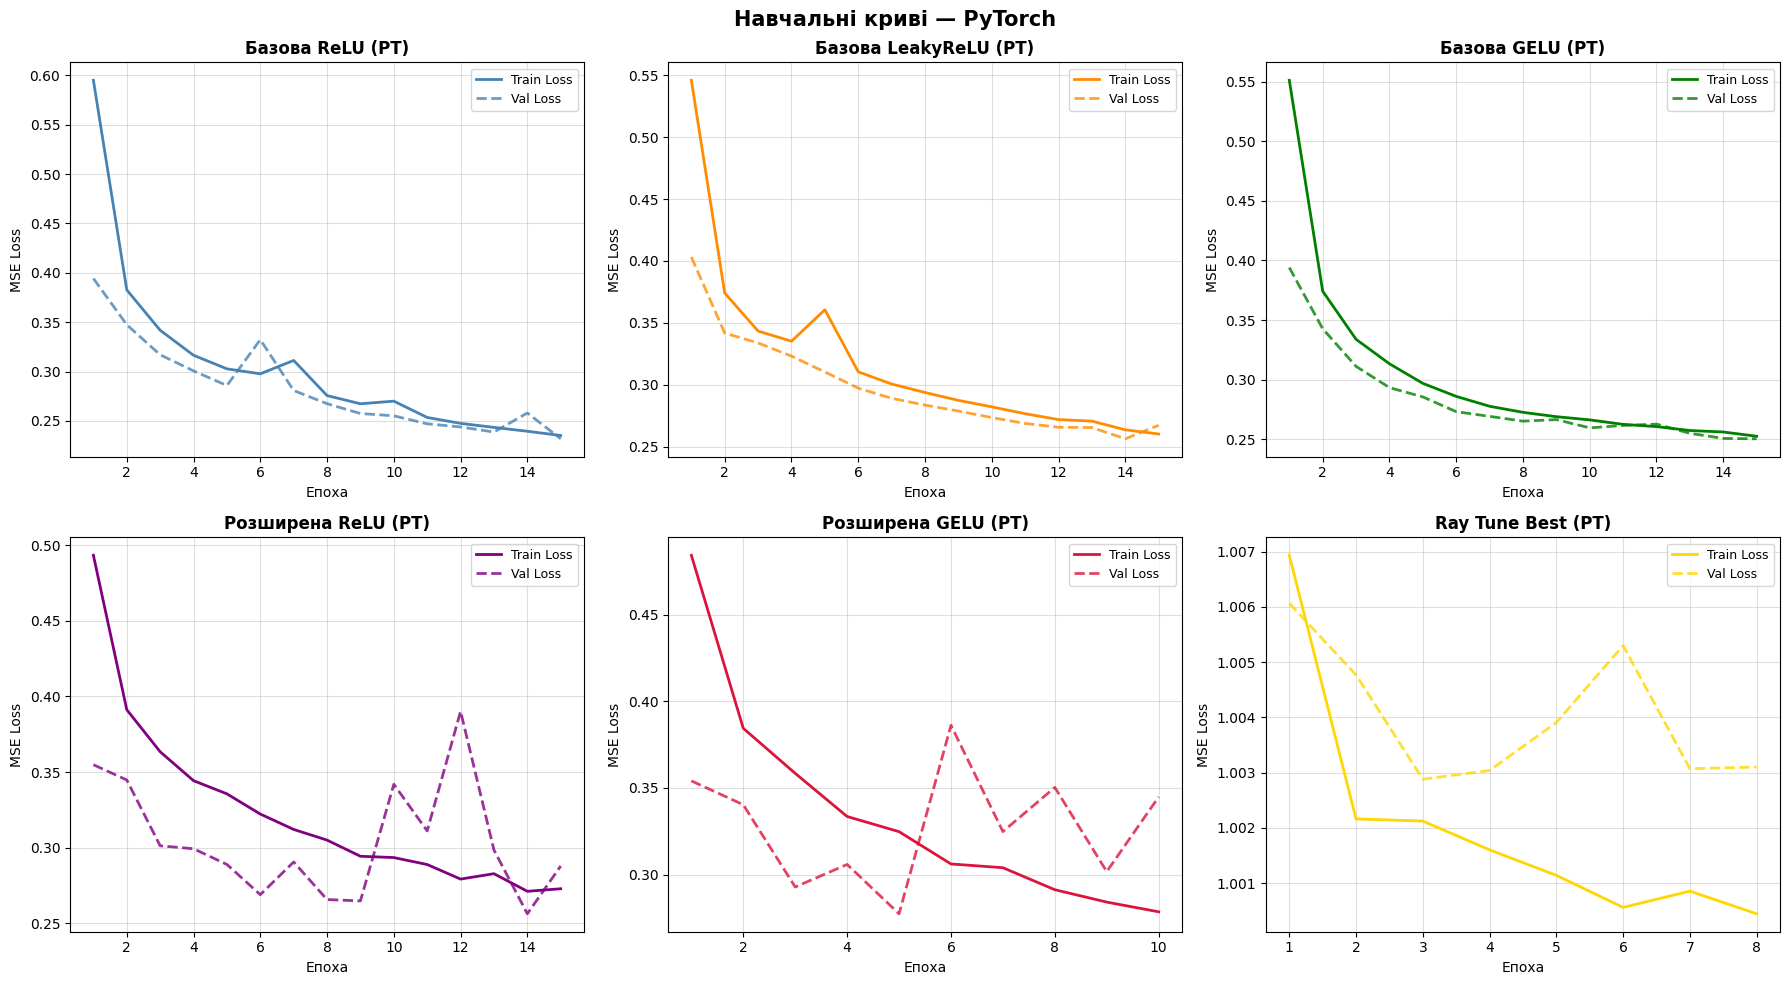

Навчальні криві збережено: lab2_learning_curves.png


In [16]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

plot_configs = [
    ('Базова ReLU (PT)',      histories_basic_pt.get('relu'),      'steelblue'),
    ('Базова LeakyReLU (PT)', histories_basic_pt.get('leaky_relu'),'darkorange'),
    ('Базова GELU (PT)',      histories_basic_pt.get('gelu'),      'green'),
    ('Розширена ReLU (PT)',   histories_adv_pt.get('relu'),        'purple'),
    ('Розширена GELU (PT)',   histories_adv_pt.get('gelu'),        'crimson'),
    ('Ray Tune Best (PT)',    history_best_rt,                     'gold'),
]

for i, (title, hist, color) in enumerate(plot_configs):
    if hist is None:
        continue
    ax = axes[i]
    ep = range(1, len(hist['train_loss']) + 1)
    ax.plot(ep, hist['train_loss'], color=color, linewidth=2, label='Train Loss')
    ax.plot(ep, hist['val_loss'],   color=color, linewidth=2, linestyle='--',
            label='Val Loss', alpha=0.8)
    ax.set_title(title, fontweight='bold', fontsize=12)
    ax.set_xlabel('Епоха')
    ax.set_ylabel('MSE Loss')
    ax.legend(fontsize=9)
    ax.grid(alpha=0.4)

plt.suptitle('Навчальні криві — PyTorch', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('lab2_learning_curves.png', dpi=120, bbox_inches='tight')
plt.show()
print('Навчальні криві збережено: lab2_learning_curves.png')

=== Результати PyTorch (сортовано за RMSE) ===


'          Модель    MSE   RMSE    MAE     R²\n      basic_relu 0.3246 0.5698 0.3999 0.7523\n      basic_gelu 0.3436 0.5862 0.4183 0.7378\n   advanced_relu 0.3447 0.5871 0.4045 0.7370\nbasic_leaky_relu 0.3574 0.5978 0.4208 0.7273\n   advanced_gelu 0.3804 0.6167 0.4307 0.7098\n    raytune_best 1.3065 1.1430 0.9060 0.0031'

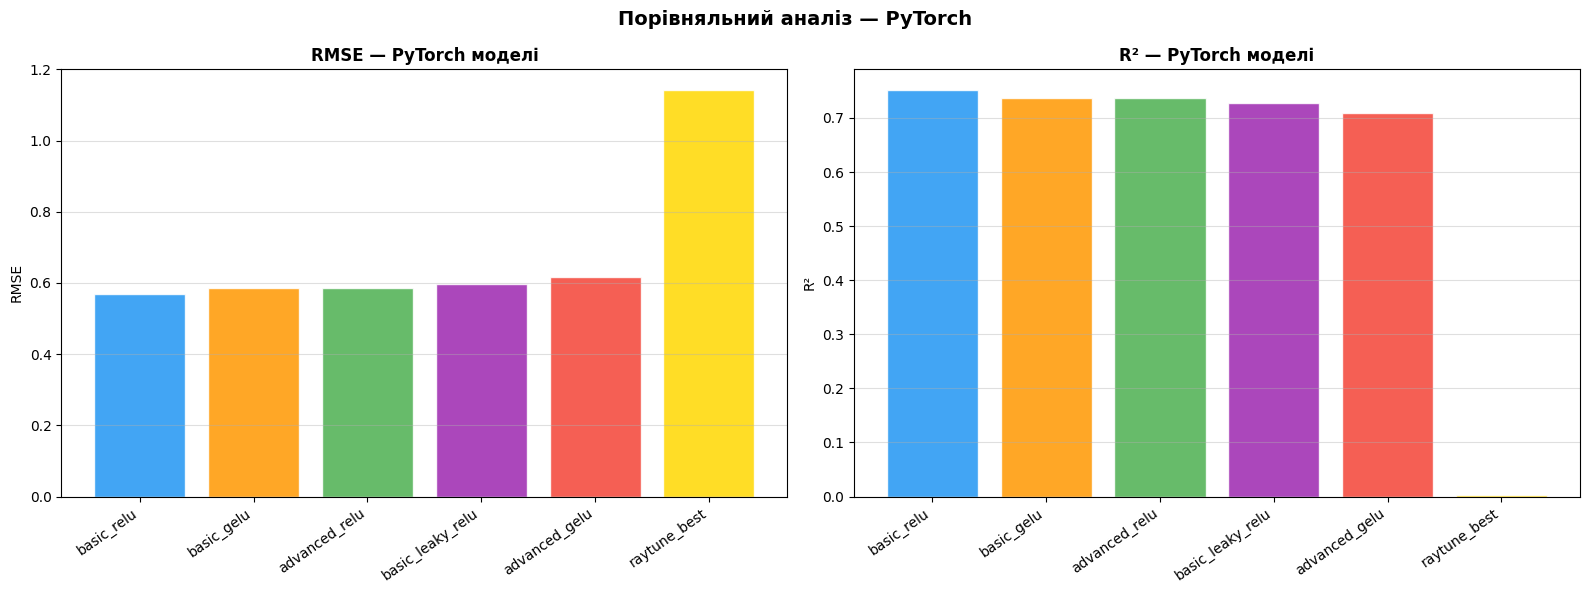

In [17]:
rows = []
for name, m in results_pt.items():
    rows.append({'Модель': name, 'MSE': round(m['mse'],4),
                 'RMSE': round(m['rmse'],4), 'MAE': round(m['mae'],4), 'R²': round(m['r2'],4)})
df_res_pt = pd.DataFrame(rows).sort_values('RMSE')
print('=== Результати PyTorch (сортовано за RMSE) ===')
display(df_res_pt.to_string(index=False))

bar_colors = ['#2196F3','#FF9800','#4CAF50','#9C27B0','#F44336','#FFD700']
x = range(len(df_res_pt))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].bar(x, df_res_pt['RMSE'], color=bar_colors[:len(df_res_pt)], alpha=0.85, edgecolor='white')
axes[0].set_xticks(x)
axes[0].set_xticklabels(df_res_pt['Модель'], rotation=35, ha='right', fontsize=10)
axes[0].set_ylabel('RMSE')
axes[0].set_title('RMSE — PyTorch моделі', fontweight='bold')
axes[0].grid(axis='y', alpha=0.4)

axes[1].bar(x, df_res_pt['R²'], color=bar_colors[:len(df_res_pt)], alpha=0.85, edgecolor='white')
axes[1].set_xticks(x)
axes[1].set_xticklabels(df_res_pt['Модель'], rotation=35, ha='right', fontsize=10)
axes[1].set_ylabel('R²')
axes[1].set_title('R² — PyTorch моделі', fontweight='bold')
axes[1].grid(axis='y', alpha=0.4)

plt.suptitle('Порівняльний аналіз — PyTorch', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('lab2_metrics_comparison.png', dpi=120, bbox_inches='tight')
plt.show()

In [18]:
# Завантажуємо результати Lab 1 (якщо є) або вводимо вручну
# Нижче вставте або оновіть значення з виводу Lab 1
tf_results_reference = {
    'basic_relu':     {'rmse': None, 'r2': None},
    'basic_gelu':     {'rmse': None, 'r2': None},
    'advanced_relu':  {'rmse': None, 'r2': None},
    'advanced_gelu':  {'rmse': None, 'r2': None},
    'optuna_best':    {'rmse': None, 'r2': None},
}
print('Примітка: запустіть Lab 1, щоб отримати TF-метрики і вставте їх у tf_results_reference.')
print()
print('=== ПОТОЧНІ PyTorch результати ===')
display(df_res_pt.to_string(index=False))

Примітка: запустіть Lab 1, щоб отримати TF-метрики і вставте їх у tf_results_reference.

=== ПОТОЧНІ PyTorch результати ===


'          Модель    MSE   RMSE    MAE     R²\n      basic_relu 0.3246 0.5698 0.3999 0.7523\n      basic_gelu 0.3436 0.5862 0.4183 0.7378\n   advanced_relu 0.3447 0.5871 0.4045 0.7370\nbasic_leaky_relu 0.3574 0.5978 0.4208 0.7273\n   advanced_gelu 0.3804 0.6167 0.4307 0.7098\n    raytune_best 1.3065 1.1430 0.9060 0.0031'

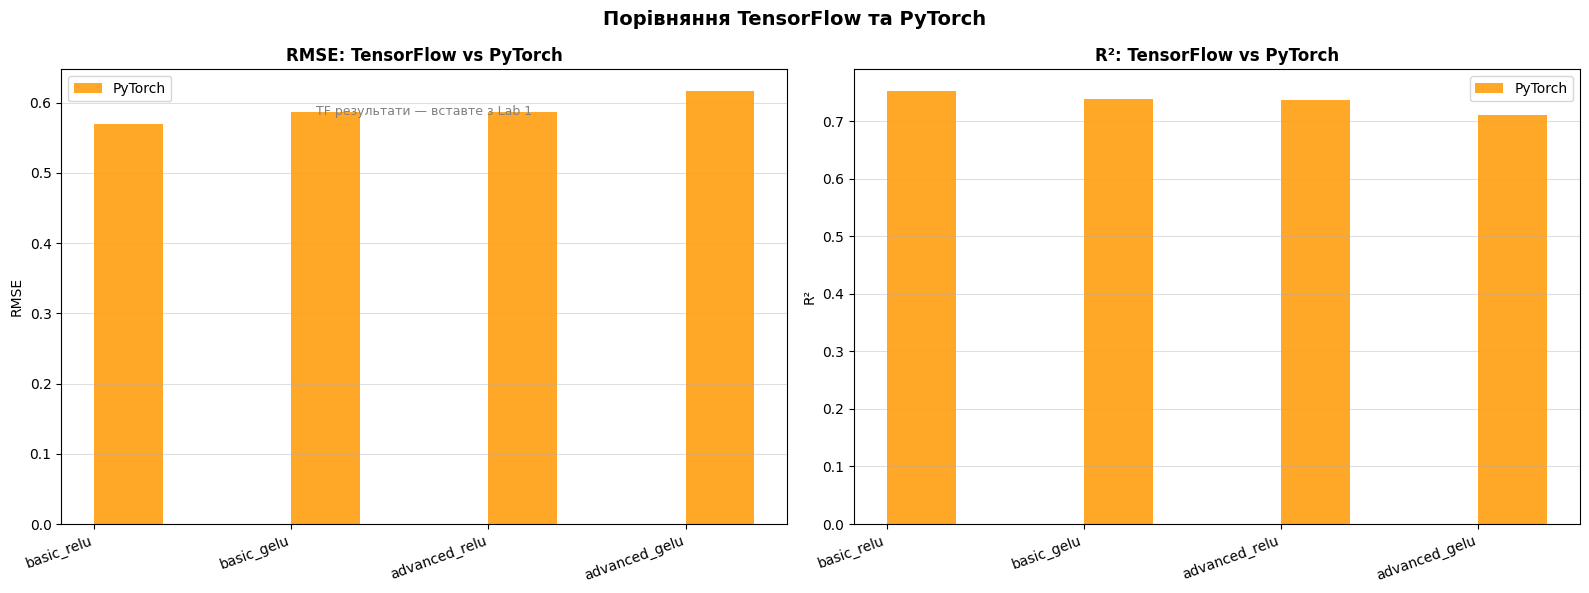

In [19]:
# Загальний порівняльний графік TF vs PyTorch (базові та кращі моделі)
models_compare = ['basic_relu', 'basic_gelu', 'advanced_relu', 'advanced_gelu']
pt_rmse = [results_pt.get(k, {}).get('rmse', np.nan) for k in models_compare]
pt_r2   = [results_pt.get(k, {}).get('r2',   np.nan) for k in models_compare]

x = np.arange(len(models_compare))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

bars_pt = axes[0].bar(x + width/2, pt_rmse, width, label='PyTorch', color='#FF9800', alpha=0.85)
axes[0].set_xticks(x)
axes[0].set_xticklabels(models_compare, rotation=20, ha='right', fontsize=10)
axes[0].set_ylabel('RMSE')
axes[0].set_title('RMSE: TensorFlow vs PyTorch', fontweight='bold')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.4)
axes[0].text(0.5, 0.9, 'TF результати — вставте з Lab 1',
              transform=axes[0].transAxes, ha='center', color='gray', fontsize=9)

bars_pt2 = axes[1].bar(x + width/2, pt_r2, width, label='PyTorch', color='#FF9800', alpha=0.85)
axes[1].set_xticks(x)
axes[1].set_xticklabels(models_compare, rotation=20, ha='right', fontsize=10)
axes[1].set_ylabel('R²')
axes[1].set_title('R²: TensorFlow vs PyTorch', fontweight='bold')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.4)

plt.suptitle('Порівняння TensorFlow та PyTorch', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('lab2_tf_vs_pytorch.png', dpi=120, bbox_inches='tight')
plt.show()